## Natural Language Processing
Natural Language Processing(**NLP**) has become an essential skill for data scientists as organizations increasingly seek to extract value from vast amounts of unstructured text data.

We'll explore the **concepts** including unique challenges of working with human language data and then **practical** techniques for preparing and working with text data. 

For concepts we will cover:
- Scope of NLP
- Challenges human language presents in computation
- Linguistic levels involved in NLP
- Real-world applications

For practical skills we will cover:
- Text cleaning techniques
- Text normalization with NLTK
- Building a complete text preprocessing pipeline
- Text exploration and analysis

NLP covers several levels:
- lexical(words)
- syntactic(grammar and structure)
- semantic(meaning)
- pragmatic(intent in context)

In [15]:
sentence_A = "Dogs normally chase cats and     love playing in     the rain."
sentence_B = "This dog was scratched by your cat."

"The dog chased the cat."
"The cat chased the dog."

'The cat chased the dog.'

In [5]:
"""
good

gooooood

gud

gd

"""

'\ngood\n\ngooooood\n\ngud\n\ngd\n\n'

In [13]:
#imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import seaborn as sns

In [16]:
sentence_A

'Dogs normally chase cats and     love playing in     the rain.'

In [17]:
sentence_B

'This dog was scratched by your cat.'

During text processing, we use NLTK library. This library was built to help us with the challenges of working with human language.

What happens during text processing?
1. Remove irrelevant characters
2. Normalization
3. Stop word removal(dimensionality reduction)
4. Once this is achieved, we move into tokenization.
5. Reducing the word to its base form(a form of dimensionality reduction)
    - Stemming
    - Lemmatization
6. POS tagging 
7. Named entity recognition

In [ ]:
# !pip install nltk

In [19]:
#import one text from nltk
import nltk
import re
import string
from collections import Counter


#download corpuses
# nltk.download(['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4',
#                'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng',
#                'gutenberg'])

In [20]:
from nltk.corpus import gutenberg

#load Alice in Wonderland
text = gutenberg.raw('carroll-alice.txt')[:3000]


print(text[:800])

[Alice's Adventures in Wonderland by Lewis Carroll 1865]

CHAPTER I. Down the Rabbit-Hole

Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once or twice she had peeped into the
book her sister was reading, but it had no pictures or conversations in
it, 'and what is the use of a book,' thought Alice 'without pictures or
conversation?'

So she was considering in her own mind (as well as she could, for the
hot day made her feel very sleepy and stupid), whether the pleasure
of making a daisy-chain would be worth the trouble of getting up and
picking the daisies, when suddenly a White Rabbit with pink eyes ran
close by her.

There was nothing so VERY remarkable in that; nor did Alice think it so
VERY much out of the way to hear the Rabbit


In [39]:
test_tweet = """ 
OMG!!! Kenya is trending AGAIN 😂 😂😂            #KOX #Nairobi               #MoringaSchool @chacha check this website out
https://www.moringaschool.com

"""

print(test_tweet)

 
OMG!!! Kenya is trending AGAIN 😂 😂😂            #KOX #Nairobi               #MoringaSchool @chacha check this website out
https://www.moringaschool.com




In [41]:
#removing irrelevant characters
#normalization ---> lowercase everything
#urls
#text(remove emojis)
#remove extra white space
def clean_text(text):
    text = text.lower()   #lower case
    text = re.sub(r'https?://\S+', '', text) #URLS
    text = re.sub(r'\[.*?\]', '', text) #remove the title that is in brackets[]
    text = re.sub(r'^[a-z\s]', '', text) #keep letters only
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print(test_tweet)
cleaned_tweet = clean_text(test_tweet)
print(cleaned_tweet)
    

 
OMG!!! Kenya is trending AGAIN 😂 😂😂            #KOX #Nairobi               #MoringaSchool @chacha check this website out
https://www.moringaschool.com


omg!!! kenya is trending again 😂 😂😂 #kox #nairobi #moringaschool @chacha check this website out


In [43]:
print(text)

[Alice's Adventures in Wonderland by Lewis Carroll 1865]

CHAPTER I. Down the Rabbit-Hole

Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once or twice she had peeped into the
book her sister was reading, but it had no pictures or conversations in
it, 'and what is the use of a book,' thought Alice 'without pictures or
conversation?'

So she was considering in her own mind (as well as she could, for the
hot day made her feel very sleepy and stupid), whether the pleasure
of making a daisy-chain would be worth the trouble of getting up and
picking the daisies, when suddenly a White Rabbit with pink eyes ran
close by her.

There was nothing so VERY remarkable in that; nor did Alice think it so
VERY much out of the way to hear the Rabbit say to itself, 'Oh dear!
Oh dear! I shall be late!' (when she thought it over afterwards, it
occurred to her that she ought to have wondered at this, but at the time
it all seemed quite natural); but

In [48]:
print(text[:500])

[Alice's Adventures in Wonderland by Lewis Carroll 1865]

CHAPTER I. Down the Rabbit-Hole

Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once or twice she had peeped into the
book her sister was reading, but it had no pictures or conversations in
it, 'and what is the use of a book,' thought Alice 'without pictures or
conversation?'

So she was considering in her own mind (as well as she could, for the
hot day made her feel very sleepy an


In [49]:
cleaned_text = clean_text(text)

print(cleaned_text[:500])

chapter i. down the rabbit-hole alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, 'and what is the use of a book,' thought alice 'without pictures or conversation?' so she was considering in her own mind (as well as she could, for the hot day made her feel very sleepy and stupid), whether the pleasure of making a daisy-chain woul


In [53]:
#tokenization
from nltk.tokenize import word_tokenize, sent_tokenize


sentences = sent_tokenize(cleaned_text)

print(len(sentences))

22


In [54]:
print(sentences[:3])

["chapter i. down the rabbit-hole alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, 'and what is the use of a book,' thought alice 'without pictures or conversation?'", 'so she was considering in her own mind (as well as she could, for the hot day made her feel very sleepy and stupid), whether the pleasure of making a daisy-chain would be worth the trouble of getting up and picking the daisies, when suddenly a white rabbit with pink eyes ran close by her.', "there was nothing so very remarkable in that; nor did alice think it so very much out of the way to hear the rabbit say to itself, 'oh dear!"]


In [64]:
tweet_tokens = word_tokenize(cleaned_tweet)

print(len(tweet_tokens))


22


In [58]:
print(cleaned_tweet)

omg!!! kenya is trending again 😂 😂😂 #kox #nairobi #moringaschool @chacha check this website out


In [57]:
print(tweet_tokens)

['omg', '!', '!', '!', 'kenya', 'is', 'trending', 'again', '😂', '😂😂', '#', 'kox', '#', 'nairobi', '#', 'moringaschool', '@', 'chacha', 'check', 'this', 'website', 'out']


In [59]:
type(tweet_tokens)

list

In [60]:
tokens = word_tokenize(cleaned_text)

print(len(tokens))


654


In [66]:
#stop word removal
from nltk.corpus import stopwords


#english stopwords
stop_words = set(stopwords.words('english'))

tweet_tokens_u = [t for t in tweet_tokens if t not in stop_words]

print(len(tweet_tokens_u))

18


In [65]:
print(tweet_tokens)


['omg', '!', '!', '!', 'kenya', 'is', 'trending', 'again', '😂', '😂😂', '#', 'kox', '#', 'nairobi', '#', 'moringaschool', '@', 'chacha', 'check', 'this', 'website', 'out']


In [67]:
print(tweet_tokens_u)

['omg', '!', '!', '!', 'kenya', 'trending', '😂', '😂😂', '#', 'kox', '#', 'nairobi', '#', 'moringaschool', '@', 'chacha', 'check', 'website']


In [69]:
tokens_c = [t for t in tokens if t not in stop_words]

print(len(tokens_c))

333


In [68]:
print(len(tokens))


654


In [ ]:
'again'

'not again'

In [72]:
#pos tagging usually comes before lemmatization and stopword removal
sentence_B

'This dog was scratched by your cat.'

In [73]:
pos_tags = nltk.pos_tag(word_tokenize(sentence_B))


print(pos_tags)

[('This', 'DT'), ('dog', 'NN'), ('was', 'VBD'), ('scratched', 'VBN'), ('by', 'IN'), ('your', 'PRP$'), ('cat', 'NN'), ('.', '.')]


In [74]:
help(nltk.pos_tag)

Help on function pos_tag in module nltk.tag:

pos_tag(tokens, tagset=None, lang='eng')
    Use NLTK's currently recommended part of speech tagger to
    tag the given list of tokens.
    
        >>> from nltk.tag import pos_tag
        >>> from nltk.tokenize import word_tokenize
        >>> pos_tag(word_tokenize("John's big idea isn't all that bad.")) # doctest: +NORMALIZE_WHITESPACE
        [('John', 'NNP'), ("'s", 'POS'), ('big', 'JJ'), ('idea', 'NN'), ('is', 'VBZ'),
        ("n't", 'RB'), ('all', 'PDT'), ('that', 'DT'), ('bad', 'JJ'), ('.', '.')]
        >>> pos_tag(word_tokenize("John's big idea isn't all that bad."), tagset='universal') # doctest: +NORMALIZE_WHITESPACE
        [('John', 'NOUN'), ("'s", 'PRT'), ('big', 'ADJ'), ('idea', 'NOUN'), ('is', 'VERB'),
        ("n't", 'ADV'), ('all', 'DET'), ('that', 'DET'), ('bad', 'ADJ'), ('.', '.')]
    
    NB. Use `pos_tag_sents()` for efficient tagging of more than one sentence.
    
    :param tokens: Sequence of tokens to be tagged

In [86]:
# stemming
from nltk.stem import PorterStemmer


stemmer = PorterStemmer()

list_of_words = ['playing', 'played', 'was', 'dogs', 'chase', 'scratched', 'studies', 'teeth', 'alumni', 'students']

print([(w, stemmer.stem(w)) for w in list_of_words])

[('playing', 'play'), ('played', 'play'), ('was', 'wa'), ('dogs', 'dog'), ('chase', 'chase'), ('scratched', 'scratch'), ('studies', 'studi'), ('teeth', 'teeth'), ('alumni', 'alumni'), ('students', 'student')]


In [79]:
#lemmatization
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

print(lemmatizer.lemmatize('studies'))
print(lemmatizer.lemmatize('was', pos='v'))

study
be


In [83]:
print(lemmatizer.lemmatize('teeth', pos='n'))


teeth


In [85]:
# help(lemmatizer.lemmatize)

In [10]:
#n-grams visualization

In [11]:
#bag of words

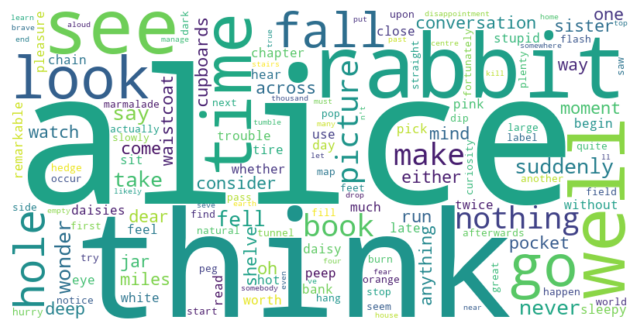

In [88]:
#word cloud
from wordcloud import WordCloud

lemmas_c = [lemmatizer.lemmatize(w, pos='v') for w in tokens_c]
# lemmas = [lemmatizer.lemmatize(w, pos='v') for w in tokens]

wc = WordCloud(width=800, height=400, background_color = 'white', colormap='viridis').generate(' '.join(lemmas_c))

plt.figure(figsize=(8, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()

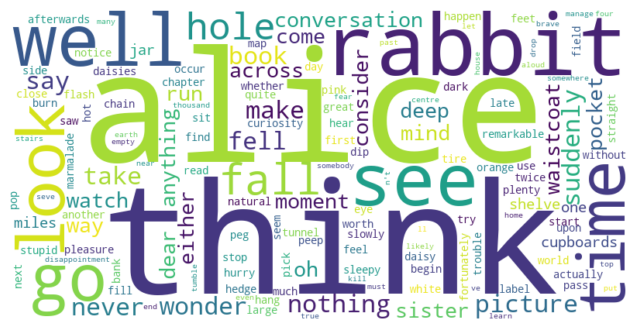

In [89]:
#word cloud
from wordcloud import WordCloud

# lemmas_c = [lemmatizer.lemmatize(w, pos='v') for w in tokens_c]
lemmas = [lemmatizer.lemmatize(w, pos='v') for w in tokens]

wc = WordCloud(width=800, height=400, background_color = 'white', colormap='viridis').generate(' '.join(lemmas))

plt.figure(figsize=(8, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()